Importing libraries

In [46]:
import pandas as pd
import numpy as np
import matplotlib as mp
import matplotlib.pyplot as plt

importing dataset

In [47]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/TIH_Data/yield_df.csv')

yearly_yield = df.groupby('Year')['hg/ha_yield'].sum().reset_index()

print(yearly_yield.head())

X = yearly_yield['Year'].values.reshape(-1, 1)
y = yearly_yield['hg/ha_yield'].values.reshape(-1, 1)

   Year  hg/ha_yield
0  1990     77344486
1  1991     77194758
2  1992     81570324
3  1993     82528465
4  1994     83658971


ploting the X and y

Normalinzin the Years before applying linear regression

In [48]:
XMean = np.mean(X)
XStd = np.std(X)
X = (X - np.mean(X)) / np.std(X)

Making the data noicy first

In [49]:
# We will add positive-only noise to only the second half of the data points
np.random.seed(44)

# Reset X back to the clean standardized version first
X_clean = (yearly_yield['Year'].values.reshape(-1, 1) - XMean) / XStd

# Generate strictly positive noise (using an exponential or half-normal distribution)
positive_noise = np.random.exponential(scale=0.5, size=X_clean.shape)

# Create a mask to apply noise to only one section (e.g., indices where standardized X > 0)
section_mask = (X_clean > 0).astype(float)

# Apply the directional noise only to that specific section
X_noisy = X_clean + (positive_noise * section_mask)

# Update our active feature variable
X = X_noisy

In [50]:
w = 0.0
b = 0.0
lr = 0.01
epochs = 500
loss = []
X=X_noisy
for epoch in range(epochs):
  err=w*X+b-y
  w-=lr*2*(err*X).mean(); b-=lr*2*err.mean()
  loss.append((err**2).mean())

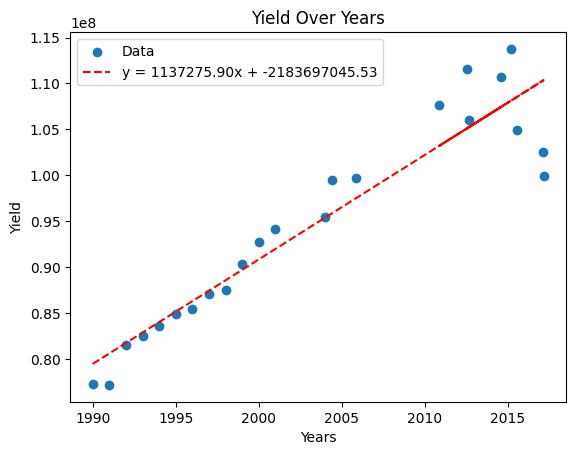

In [51]:

X_orig = (X * XStd) + XMean

w_orig = w / XStd
b_orig = b - (w * XMean / XStd)

mp.pyplot.scatter(X_orig, y, label='Data')
mp.pyplot.plot(X_orig, w_orig * X_orig + b_orig, color='red', linestyle='--',
               label=f'y = {w_orig:.2f}x + {b_orig:.2f}')

mp.pyplot.xlabel('Years')
mp.pyplot.ylabel('Yield')
mp.pyplot.title('Yield Over Years')
mp.pyplot.legend()
mp.pyplot.show()

Applying the Rigde with GridSearchCv

In [52]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# We will sweep over multiple alpha values for sklearn's Ridge
param_grid = {
    'alpha': [0.0, 0.1, 1.0, 10.0, 50.0, 100.0, 500.0]
}

# Initialize built-in Ridge regression and GridSearchCV
ridge_grid = GridSearchCV(estimator=Ridge(), param_grid=param_grid, scoring='neg_mean_squared_error', cv=5)
ridge_grid.fit(X_noisy, y)

print(f"Best alpha for sklearn Ridge: {ridge_grid.best_params_['alpha']}")
print(f"Best Cross-Validated MSE: {-ridge_grid.best_score_:.4e}")

Best alpha for sklearn Ridge: 1.0
Best Cross-Validated MSE: 4.3610e+13


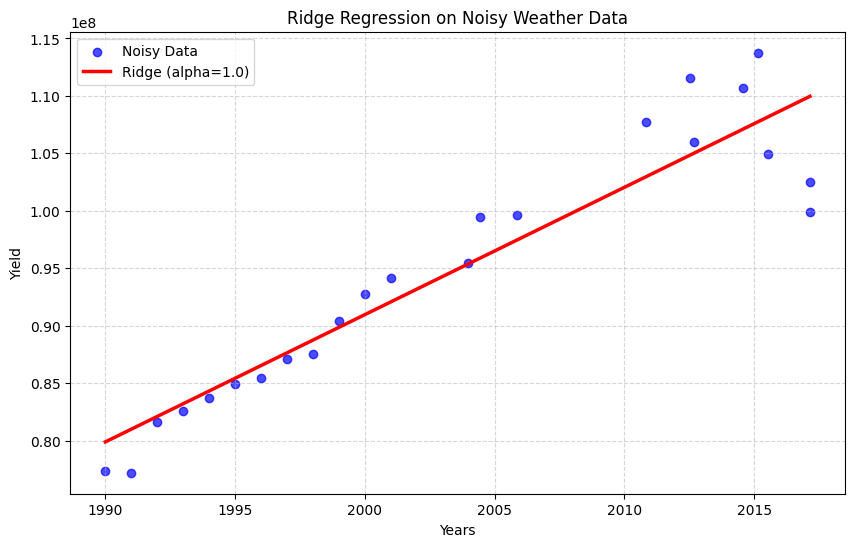

In [53]:
import matplotlib.pyplot as plt

# Get the best Ridge model from GridSearchCV
best_ridge = ridge_grid.best_estimator_

# Predict using the best Ridge model (X_noisy is on the standardized scale)
y_pred = best_ridge.predict(X_noisy)

# Map back to original year scale for visualization
X_orig = (X_noisy * XStd) + XMean

# Plot the data and the Ridge regression line
plt.figure(figsize=(10, 6))
plt.scatter(X_orig, y, color='blue', label='Noisy Data', alpha=0.7)

# Sort for clean line plotting
sort_idx = np.argsort(X_orig.flatten())
plt.plot(X_orig[sort_idx], y_pred[sort_idx], color='red', linestyle='-', linewidth=2.5,
         label=f'Ridge (alpha={ridge_grid.best_params_["alpha"]})')

plt.xlabel('Years')
plt.ylabel('Yield')
plt.title('Ridge Regression on Noisy Weather Data')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()